# 01 – Exploration & First Detectors
Loads `data/executions.csv`, explores it, and compares a **rule-based detector** with an **Isolation Forest** against the injected ground-truth labels (`is_anomaly`).

**Leakage note:** `scenario` and `is_anomaly` are ground truth. They are used *only* for evaluation, never as detector inputs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "executions.csv"
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
RANDOM_STATE = 42

df = pd.read_csv(DATA, parse_dates=["started_at", "stopped_at"])
df["is_anomaly"] = df["is_anomaly"].astype(str).str.lower().isin(["1", "true", "yes"]).astype(int)
print(df.shape)
df.head()

(477, 29)


,execution_id,workflow_id,mode,status,finished,retry_of,started_at,stopped_at,duration_s,hour_of_day,...,node_schedule_trigger_ms,node_schedule_trigger_runs,node_choose_scenario_ms,node_choose_scenario_runs,node_simulated_llm_latency_ms,node_simulated_llm_latency_runs,node_simulated_tool_call_ms,node_simulated_tool_call_runs,node_process_results_ms,node_process_results_runs
0,477,I3PR51wNSoGdt7Tz,trigger,success,True,NaN,2026-11-25 11:39:01.905+00:00,2026-11-25 11:39:04.270+00:00,2.365,11,...,0,1,8,1,2326,1,7,1,7.0,1.0
1,476,I3PR51wNSoGdt7Tz,trigger,success,True,NaN,2026-11-25 11:38:01.910+00:00,2026-11-25 11:38:03.883+00:00,1.973,11,...,1,1,8,1,1936,1,8,1,6.0,1.0
2,475,I3PR51wNSoGdt7Tz,trigger,success,True,NaN,2026-11-25 11:37:01.909+00:00,2026-11-25 11:37:05.215+00:00,3.306,11,...,0,1,8,1,3265,1,7,1,5.0,1.0
3,474,I3PR51wNSoGdt7Tz,trigger,error,False,NaN,2026-11-25 11:36:01.911+00:00,2026-11-25 11:36:08.913+00:00,7.002,11,...,0,1,11,1,2946,1,4027,1,NaN,NaN
4,473,I3PR51wNSoGdt7Tz,trigger,success,True,NaN,2026-11-25 11:35:01.909+00:00,2026-11-25 11:35:03.126+00:00,1.217,11,...,0,1,10,1,1177,1,6,1,7.0,1.0


## 1. Data overview

In [2]:
print("Anomaly rate:", round(df["is_anomaly"].mean(), 3), f"({df['is_anomaly'].sum()} of {len(df)})")
display(df["status"].value_counts())
display(df["scenario"].value_counts())
display(df.isna().sum()[df.isna().sum() > 0])

Anomaly rate: 0.182 (87 of 477)


status
success    438
error       39
Name: count, dtype: int64

scenario
normal           390
hard_failure      32
slow              24
flaky             18
payload_spike     13
Name: count, dtype: int64

retry_of                     477
error_message                438
error_node                   438
node_process_results_ms       39
node_process_results_runs     39
dtype: int64

In [3]:
ms_cols = [c for c in df.columns if c.startswith("node_") and c.endswith("_ms")]
df[["duration_s", "nodes_executed", "items_out_total"] + ms_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
duration_s,477.0,4.428350,6.653639,0.065,1.95,2.884,3.711,44.267
nodes_executed,477.0,4.918239,0.274288,4.000,5.00,5.000,5.000,5.000
items_out_total,477.0,21.389937,77.957345,3.000,8.00,9.000,10.000,589.000
node_schedule_trigger_ms,477.0,0.620545,1.637480,0.000,0.00,0.000,1.000,21.000
node_choose_scenario_ms,477.0,11.268344,12.590317,5.000,7.00,9.000,11.000,165.000
node_simulated_llm_latency_ms,477.0,4028.719078,6633.065184,1005.000,1867.00,2645.000,3415.000,44225.000
node_simulated_tool_call_ms,477.0,366.863732,1136.079350,4.000,6.00,7.000,9.000,4089.000
node_process_results_ms,438.0,7.712329,7.181172,4.000,5.00,6.000,8.000,128.000


## 2. Visual exploration

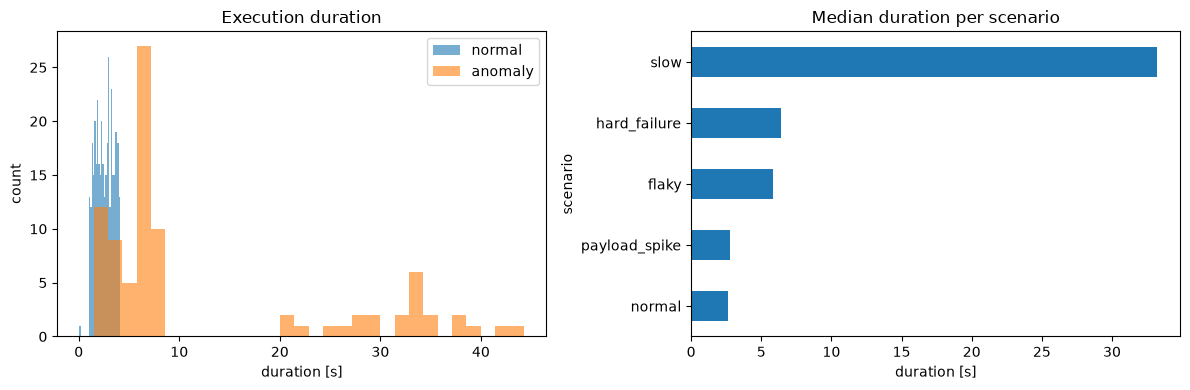

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, g in df.groupby("is_anomaly"):
    axes[0].hist(g["duration_s"], bins=30, alpha=0.6, label="anomaly" if label else "normal")
axes[0].set(title="Execution duration", xlabel="duration [s]", ylabel="count"); axes[0].legend()

df.groupby("scenario")["duration_s"].median().sort_values().plot.barh(ax=axes[1])
axes[1].set(title="Median duration per scenario", xlabel="duration [s]")
plt.tight_layout(); plt.savefig(RESULTS / "01_duration.png", dpi=150); plt.show()

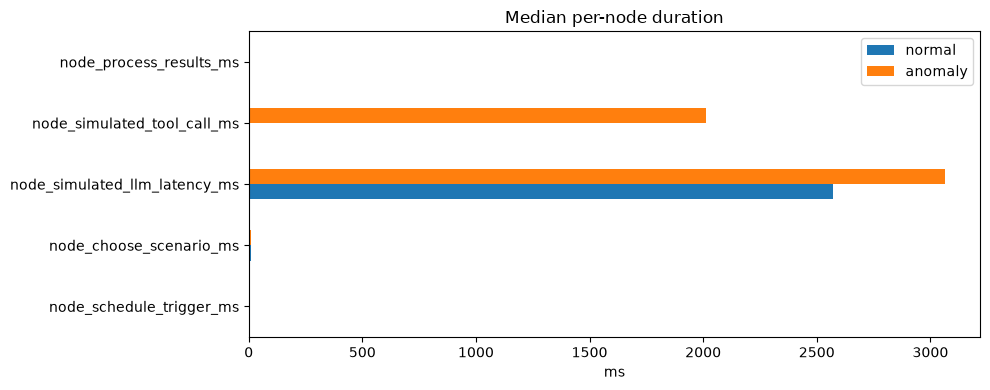

In [5]:
ax = df.groupby("is_anomaly")[ms_cols].median().T.plot.barh(figsize=(10, 4))
ax.set(title="Median per-node duration", xlabel="ms"); ax.legend(["normal", "anomaly"])
plt.tight_layout(); plt.savefig(RESULTS / "01_node_durations.png", dpi=150); plt.show()

## 3. Rule-based detector
Rules use only observable execution data. Thresholds are robust statistics (median + k·MAD), so a few outliers don't shift them.

**Assumption:** k = 3.5 (common default for modified z-scores). Tune and justify in the thesis.

In [6]:
K = 3.5

def mad_upper(s, k=K):
    s = s.dropna()
    med = s.median()
    mad = (s - med).abs().median() * 1.4826
    return med + k * mad if mad > 0 else s.quantile(0.99)

rules = pd.DataFrame(index=df.index)
rules["R1_failed"] = (df["status"].astype(str).str.lower() != "success") | (df["has_error"].astype(str).str.lower().isin(["1", "true"]))
rules["R2_long_duration"] = df["duration_s"] > mad_upper(df["duration_s"])
rules["R3_unusual_path"] = df["nodes_executed"] != df["nodes_executed"].mode()[0]
for c in ms_cols:
    rules[f"R4_slow_{c[5:-3]}"] = df[c] > mad_upper(df[c])

df["rule_flag"] = rules.any(axis=1).astype(int)
print("Rule triggers:"); display(rules.sum())

Rule triggers:


R1_failed                        39
R2_long_duration                 31
R3_unusual_path                  39
R4_slow_schedule_trigger          4
R4_slow_choose_scenario          29
R4_slow_simulated_llm_latency    24
R4_slow_simulated_tool_call      84
R4_slow_process_results          48
dtype: int64

## 4. Isolation Forest
Numeric features only. **Assumption:** contamination = 0.2, a fixed prior that is *not* tuned on the labels. Threshold-free performance is reported as ROC-AUC.

In [7]:
feature_cols = ["duration_s", "nodes_executed", "items_out_total", "hour_of_day"] + ms_cols \
    + [c for c in df.columns if c.startswith("node_") and c.endswith("_runs")]
X = df[feature_cols].astype(float).fillna(0)          # missing node = not executed
X["has_error"] = df["has_error"].astype(str).str.lower().isin(["1", "true"]).astype(int)
X_scaled = StandardScaler().fit_transform(X)

iso = IsolationForest(n_estimators=300, contamination=0.2, random_state=RANDOM_STATE)
df["if_flag"] = (iso.fit_predict(X_scaled) == -1).astype(int)
df["if_score"] = -iso.score_samples(X_scaled)        # higher = more anomalous

## 5. Evaluation

In [8]:
def evaluate(name, y_pred, y_true=df["is_anomaly"], score=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"method": name, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "precision": round(precision_score(y_true, y_pred, zero_division=0), 3),
            "recall": round(recall_score(y_true, y_pred, zero_division=0), 3),
            "F1": round(f1_score(y_true, y_pred, zero_division=0), 3),
            "ROC-AUC": round(roc_auc_score(y_true, score), 3) if score is not None else None}

df["hybrid_flag"] = (df["rule_flag"] | df["if_flag"]).astype(int)
results = pd.DataFrame([
    evaluate("Rule-based", df["rule_flag"]),
    evaluate("Isolation Forest", df["if_flag"], score=df["if_score"]),
    evaluate("Hybrid (OR)", df["hybrid_flag"]),
])
results.to_csv(RESULTS / "01_metrics.csv", index=False)
results

,method,TP,FP,FN,TN,precision,recall,F1,ROC-AUC
0,Rule-based,70,62,17,328,0.530,0.805,0.639,NaN
1,Isolation Forest,81,15,6,375,0.844,0.931,0.885,0.947
2,Hybrid (OR),81,62,6,328,0.566,0.931,0.704,NaN


### Detection rate per anomaly scenario

In [9]:
df[df["is_anomaly"] == 1].groupby("scenario")[["rule_flag", "if_flag", "hybrid_flag"]].mean().round(2)

,rule_flag,if_flag,hybrid_flag
scenario,,,
flaky,0.67,0.67,0.67
hard_failure,1.00,1.00,1.00
payload_spike,0.15,1.00,1.00
slow,1.00,1.00,1.00


### False positives (normal runs flagged)

In [10]:
df[(df["is_anomaly"] == 0) & (df["hybrid_flag"] == 1)][["execution_id", "scenario", "status", "duration_s", "rule_flag", "if_flag"]]

,execution_id,scenario,status,duration_s,rule_flag,if_flag
17,460,normal,success,1.327,1,0
21,456,normal,success,2.357,1,0
28,449,normal,success,1.320,1,0
33,444,normal,success,2.846,1,0
41,436,normal,success,2.677,1,0
...,...,...,...,...,...,...
423,54,normal,success,4.093,1,0
470,7,normal,success,1.408,1,0
473,4,normal,success,4.053,1,0
475,2,normal,success,0.065,1,1


## 6. Notes for the thesis
- **Small sample** (≈112 runs, 23 anomalies): metrics have high variance. Generate more runs, or report bootstrap confidence intervals.
- Rule thresholds are computed on the whole dataset, including anomalies. For a stricter evaluation, fit them on normal runs only, or use a train/test split by time.
- Injected anomalies are synthetic. Validate on real MagOneAI execution data once access is confirmed.